In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [2]:
# Loading The Data
df_1 = pd.read_csv("churn-bigml-80.csv")
df_2 = pd.read_csv("churn-bigml-20.csv")
df = pd.concat([df_1, df_2], ignore_index=True)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3333 entries, 0 to 3332
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   State                   3333 non-null   object 
 1   Account length          3333 non-null   int64  
 2   Area code               3333 non-null   int64  
 3   International plan      3333 non-null   object 
 4   Voice mail plan         3333 non-null   object 
 5   Number vmail messages   3333 non-null   int64  
 6   Total day minutes       3333 non-null   float64
 7   Total day calls         3333 non-null   int64  
 8   Total day charge        3333 non-null   float64
 9   Total eve minutes       3333 non-null   float64
 10  Total eve calls         3333 non-null   int64  
 11  Total eve charge        3333 non-null   float64
 12  Total night minutes     3333 non-null   float64
 13  Total night calls       3333 non-null   int64  
 14  Total night charge      3333 non-null   

In [4]:
df.head()

,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,KS,128,415,No,Yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,No,Yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,No,No,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,Yes,No,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,Yes,No,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


In [5]:
# Imports
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, roc_curve, roc_auc_score)

In [6]:
# Work on a copy of the raw data and check the class balance 
 
df_clf = df.copy()       

print(df_clf['Churn'].value_counts())
print(df_clf['Churn'].value_counts(normalize=True).round(3))

Churn
False    2850
True      483
Name: count, dtype: int64
Churn
False    0.855
True     0.145
Name: proportion, dtype: float64


### Encode Target and Binary Colmns

In [7]:
# Encoding the target and the Yes/No columns 

df_clf['Churn'] = df_clf['Churn'].astype(int)                                  # True/False -> 1/0
df_clf['International plan'] = df_clf['International plan'].map({'No': 0, 'Yes': 1})
df_clf['Voice mail plan'] = df_clf['Voice mail plan'].map({'No': 0, 'Yes': 1})
df_clf[['Churn', 'International plan', 'Voice mail plan']].head()

,Churn,International plan,Voice mail plan
0,0,0,1
1,0,0,1
2,0,0,0
3,0,1,0
4,0,1,0


### Dropping Redundant Columns

In [8]:
# Drop redundant / weak features
# Charge columns: perfectly correlated with minutes (r = 1.0), so they add multicollinearity, not information
# State: 51 levels and a weak predictor, so one-hot would add about 50 sparse columns

charge_cols = ['Total day charge', 'Total eve charge', 'Total night charge', 'Total intl charge']
df_clf = df_clf.drop(columns=charge_cols + ['State'])
df_clf.shape

(3333, 15)

In [9]:
# One-hot encoding Area code because its still a category with 3 values (drop_first avoids a redundant column)
df_clf = pd.get_dummies(df_clf, columns=['Area code'], drop_first=True, dtype=int)
df_clf.columns.tolist()

['Account length',
 'International plan',
 'Voice mail plan',
 'Number vmail messages',
 'Total day minutes',
 'Total day calls',
 'Total eve minutes',
 'Total eve calls',
 'Total night minutes',
 'Total night calls',
 'Total intl minutes',
 'Total intl calls',
 'Customer service calls',
 'Churn',
 'Area code_415',
 'Area code_510']

### Features Target and Stratisfied Split

In [10]:
# Defining features/target and splitting the data 
# stratisfy =y keeps the churn rate the same in both sets
X = df_clf.drop(columns='Churn')
y = df_clf['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(X_train.shape, X_test.shape)
print("Train churn rate:", round(y_train.mean(), 3))
print("Test churn rate:", round(y_test.mean(), 3))

(2666, 15) (667, 15)
Train churn rate: 0.145
Test churn rate: 0.145


### Scaling the Continuous Columns

In [11]:
#Scaling continuous columns only because binary columns 0/1 are already on a common scale
binary_cols = ['International plan', 'Voice mail plan'] + [c for c in X.columns if c.startswith('Area code_')]
scale_cols = [c for c in X.columns if c not in binary_cols]

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[scale_cols] = scaler.fit_transform(X_train[scale_cols])   # learn from training data only
X_test_scaled[scale_cols] = scaler.transform(X_test[scale_cols])         # apply to test (no leakage)

### Train Logistic Regression

In [12]:
# Training  Logistic Regression 
# class_weight='balanced' makes the model pay more attention to the rare churn class
log_reg = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)

y_pred = log_reg.predict(X_test_scaled)
y_prob = log_reg.predict_proba(X_test_scaled)[:, 1]    # churn probability, needed for the ROC curve

### Evaluation Metrics

In [13]:
# Evaluating beyond accuracy since it can be misleading on imbalanced data
# Recall = share of real churners we catch; precision = share of our churn flags that are right
print("Accuracy :", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall   :", round(recall_score(y_test, y_pred), 3))
print("F1       :", round(f1_score(y_test, y_pred), 3))
print("ROC AUC  :", round(roc_auc_score(y_test, y_prob), 3))
print()
print(classification_report(y_test, y_pred, target_names=['Stayed', 'Churned']))

Accuracy : 0.775
Precision: 0.371
Recall   : 0.784
F1       : 0.503
ROC AUC  : 0.836

              precision    recall  f1-score   support

      Stayed       0.95      0.77      0.85       570
     Churned       0.37      0.78      0.50        97

    accuracy                           0.78       667
   macro avg       0.66      0.78      0.68       667
weighted avg       0.87      0.78      0.80       667



### ROC Curve

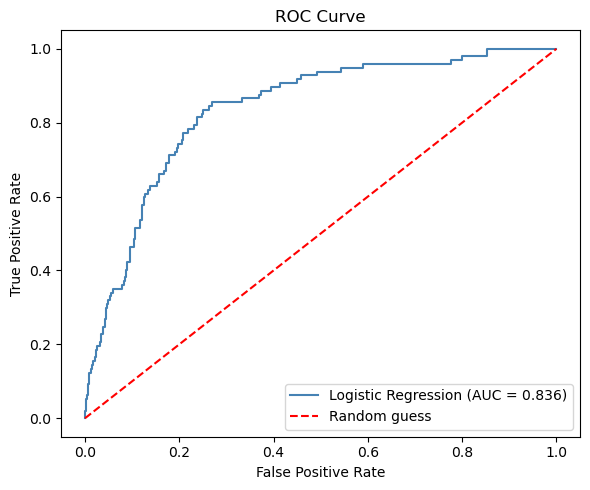

In [14]:
# The closer the curve hugs the top-left corner, the better;the dashed line is random guessing 
fpr, tpr, _ = roc_curve(y_test, y_prob)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='steelblue', label=f"Logistic Regression (AUC = {roc_auc_score(y_test, y_prob):.3f})")
plt.plot([0, 1], [0, 1], 'r--', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.tight_layout()
plt.show()

### Confusion Matrix

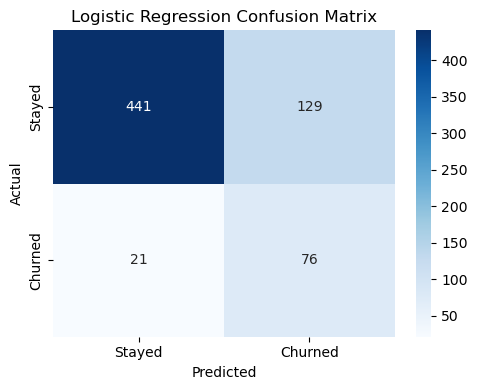

In [15]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Stayed', 'Churned'], yticklabels=['Stayed', 'Churned'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Logistic Regression Confusion Matrix')
plt.tight_layout()
plt.show()

### Coefficients

In [16]:
# What pushes churn up or down? 
# Positive = raises churn probability, negative = lowers it (continuous features are on a common scale)
coef_clf = pd.Series(log_reg.coef_[0], index=X.columns).sort_values()
coef_clf

Voice mail plan          -1.855850
Area code_510            -0.204939
Area code_415            -0.188427
Total intl calls         -0.115837
Total night calls        -0.026956
Total day calls           0.029952
Account length            0.037218
Total eve calls           0.054928
Total night minutes       0.176399
Total intl minutes        0.192171
Total eve minutes         0.381018
Number vmail messages     0.492412
Total day minutes         0.675955
Customer service calls    0.698844
International plan        2.430699
dtype: float64

### Importing other Classifiers

In [17]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

### Define the Models

In [18]:
# Defining the models to compare
# class_weight='balanced' is used wherever supported so every model treats churn as important
# (Gradient Boosting has no class_weight option, so judge it mainly by ROC AUC)
clf_models = {
    'Logistic Regression': log_reg,
    'Decision Tree': DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42),
    'SVM (RBF)': SVC(kernel='rbf', class_weight='balanced', probability=True, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
}

### Train and store predictions

In [19]:
# Training  every model and store predictions/probabilities
clf_preds = {}
clf_probs = {}

for name, model in clf_models.items():
    model.fit(X_train_scaled, y_train)
    clf_preds[name] = model.predict(X_test_scaled)
    clf_probs[name] = model.predict_proba(X_test_scaled)[:, 1]
    print(f"{name} trained")

Logistic Regression trained
Decision Tree trained
Random Forest trained
SVM (RBF) trained
Gradient Boosting trained


### Cross-Validating with AUC

In [20]:
# 5-fold stratified cross-validation on AUC, to Check that the test-set ranking is not just a lucky split
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_auc = {}

for name, model in clf_models.items():
    cv_auc[name] = cross_val_score(model, X_train_scaled, y_train, cv=skf, scoring='roc_auc').mean()
    print(f"{name}: CV AUC = {cv_auc[name]:.3f}")

Logistic Regression: CV AUC = 0.813
Decision Tree: CV AUC = 0.843
Random Forest: CV AUC = 0.903
SVM (RBF): CV AUC = 0.886
Gradient Boosting: CV AUC = 0.904


### Comparison Table

In [21]:
# Model comparison table (sorted by test ROC AUC) 
rows = []

for name in clf_models:
    rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, clf_preds[name]),
        'Precision': precision_score(y_test, clf_preds[name]),
        'Recall': recall_score(y_test, clf_preds[name]),
        'F1': f1_score(y_test, clf_preds[name]),
        'ROC AUC': roc_auc_score(y_test, clf_probs[name]),
        'CV AUC': cv_auc[name]
    })

clf_results = pd.DataFrame(rows).sort_values('ROC AUC', ascending=False).reset_index(drop=True)
clf_results.round(3)

,Model,Accuracy,Precision,Recall,F1,ROC AUC,CV AUC
0,Random Forest,0.931,0.981,0.536,0.693,0.936,0.903
1,Gradient Boosting,0.949,0.932,0.701,0.800,0.927,0.904
2,SVM (RBF),0.901,0.637,0.742,0.686,0.915,0.886
3,Decision Tree,0.913,0.664,0.814,0.731,0.908,0.843
4,Logistic Regression,0.775,0.371,0.784,0.503,0.836,0.813


### ROC Curves Together

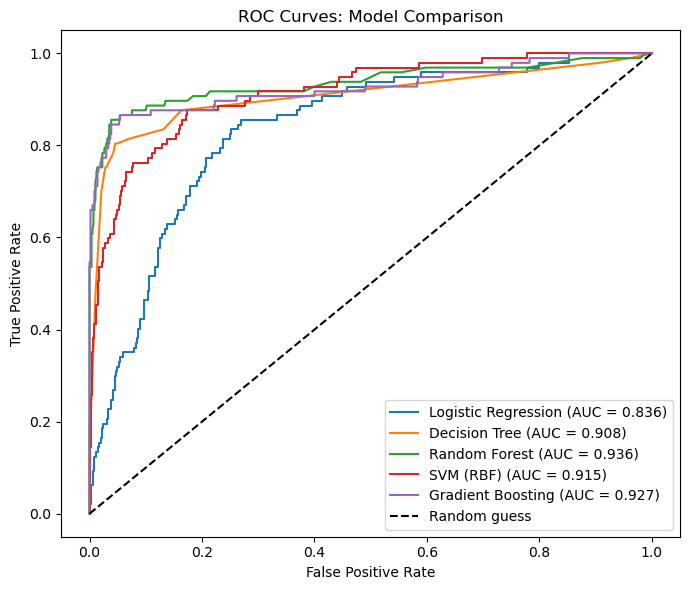

In [22]:
# ROC curves of all models on one plot
plt.figure(figsize=(7, 6))

for name in clf_models:
    fpr, tpr, _ = roc_curve(y_test, clf_probs[name])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, clf_probs[name]):.3f})")

plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves: Model Comparison')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

### Confusion Matrix of the best Model

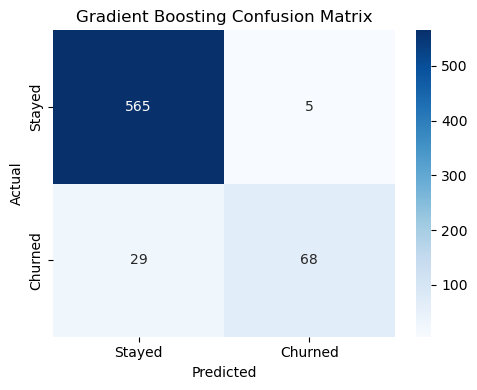

In [23]:
# Confusion matrix of the best model 
best_name = 'Gradient Boosting'     
cm_best = confusion_matrix(y_test, clf_preds[best_name])

plt.figure(figsize=(5, 4))
sns.heatmap(cm_best, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Stayed', 'Churned'], yticklabels=['Stayed', 'Churned'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'{best_name} Confusion Matrix')
plt.tight_layout()
plt.show()

### Feature Importance of best 3 Models

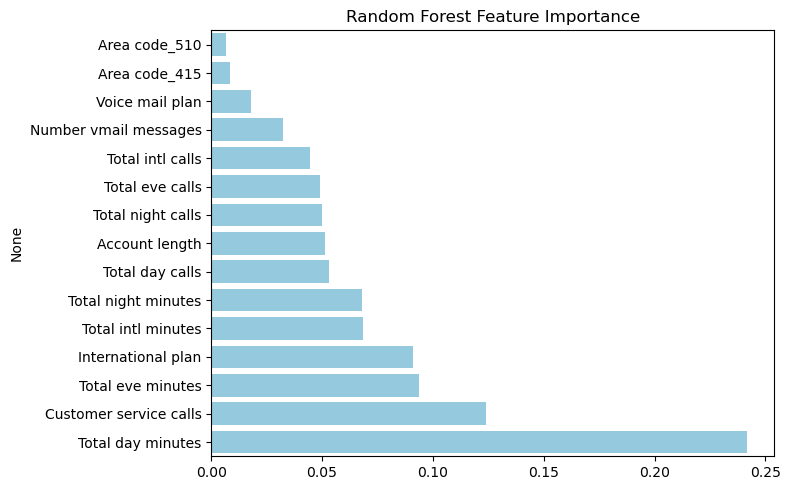

In [24]:
# Which features does the Random Forest rely on?
imp_clf = pd.Series(clf_models['Random Forest'].feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(8, 5))
sns.barplot(x=imp_clf.values, y=imp_clf.index, color='skyblue')
plt.title('Random Forest Feature Importance')
plt.tight_layout()
plt.show()

### Effect of the Decision Threshold

In [25]:
# How the decision threshold changes Gradient Boosting's results
# Lower threshold = flag more customers as churners (higher recall, lower precision)
rows = []

for t in [0.2, 0.3, 0.4, 0.5]:
    pred_t = (clf_probs['Gradient Boosting'] >= t).astype(int)
    rows.append({
        'Threshold': t,
        'Precision': precision_score(y_test, pred_t),
        'Recall': recall_score(y_test, pred_t),
        'F1': f1_score(y_test, pred_t)
    })

pd.DataFrame(rows).round(3)

,Threshold,Precision,Recall,F1
0,0.2,0.745,0.845,0.792
1,0.3,0.819,0.794,0.806
2,0.4,0.890,0.753,0.816
3,0.5,0.932,0.701,0.800


## Findings and Conclusion

**Objective:** Predict customer churn (binary) and compare Logistic Regression against other classifiers.

**Setup:** 3,333 customers, 14.5% churn (imbalanced). Stratified 80/20 split, continuous features scaled (fit on training data only), `class_weight='balanced'` used where supported. The four charge columns were dropped (perfectly correlated with minutes, r = 1.0) and `State` was dropped (51 levels, weak predictor). 
**Results**

| Model | Precision | Recall | F1 | Test AUC | CV AUC |
|---|---|---|---|---|---|
| Random Forest | 0.981 | 0.536 | 0.693 | 0.936 | 0.903 |
| Gradient Boosting | 0.932 | 0.701 | 0.800 | 0.927 | 0.904 |
| SVM (RBF) | 0.637 | 0.742 | 0.686 | 0.915 | 0.886 |
| Decision Tree | 0.664 | 0.814 | 0.731 | 0.908 | 0.843 |
| Logistic Regression | 0.371 | 0.784 | 0.503 | 0.836 | 0.813 |

**Key findings**
1. **Accuracy is misleading here.** Predicting "no churn" for everyone scores 85.5%, so models were judged on recall, precision, F1 and ROC AUC.
2. **Gradient Boosting is the best overall model** (F1 0.80, CV AUC 0.90): it caught about 70% of churners with very few false alarms.
3. **Random Forest ranked customers best (test AUC 0.936) but was too cautious at the default 0.5 threshold,** catching only 54% of churners despite 98% precision. Lowering the threshold would raise recall.
4. **Logistic Regression was the weakest performer (AUC 0.84)** but remains the most interpretable. Its coefficients show International plan (strongest), Customer service calls and Total day minutes raising churn risk, while having a voicemail plan lowers it.
5. **The Decision Tree overfit again** (test AUC 0.908 vs CV AUC 0.843), so its test score is optimistic.
6. Tree ensembles outperforming the linear model suggests non-linear relationships between usage and churn.

**Limitations:** the dataset is small and imbalanced, and Gradient Boosting was run without class weights. The decision threshold was left at 0.5 for the main comparison. In practice it should be chosen from the business cost of missing a churner versus a false alarm.

**Conclusion:** Gradient Boosting is recommended for this problem, with Logistic Regression as the interpretable baseline that confirms the main churn drivers.